# Flowboard Product Analytics

## 1. Metric System and Definitions

This analysis examines product activation, retention, funnel
conversion, experiment outcomes and user behaviour.

Metric definitions are documented in `metric_definitions.md`.

All timestamps use UTC.

In [1]:
%pip install -q google-cloud-bigquery db-dtypes scipy statsmodels seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
from google.cloud import bigquery

client = bigquery.Client(project="product-analysis-509809")

activation = client.query("""
    SELECT *
    FROM `product-analysis-509809.saas_analytics_dbt.mart_activation`
    ORDER BY acquisition_channel
""").to_dataframe()

display(activation)

NotFound: 404 Not found: Table product-analysis-509809:saas_analytics_dbt.stg_users was not found in location US; reason: notFound, message: Not found: Table product-analysis-509809:saas_analytics_dbt.stg_users was not found in location US

Location: US
Job ID: 9e6196ef-0be7-4408-8773-64a4b361b84d


,acquisition_channel,total_signups,activated_d7_users,d7_activation_rate_pct,median_time_to_activate_days,p90_time_to_activate_days
5,referral,9085,3970,43.70,4.069757,67.032940
4,partner,4922,1874,38.07,5.578021,73.002060
2,organic_search,12145,4581,37.72,5.857350,73.863542
0,content,7449,2696,36.19,5.238704,78.141389
1,direct,7470,2551,34.15,6.247674,81.334595
3,paid_search,8929,2493,27.92,7.692454,88.125949


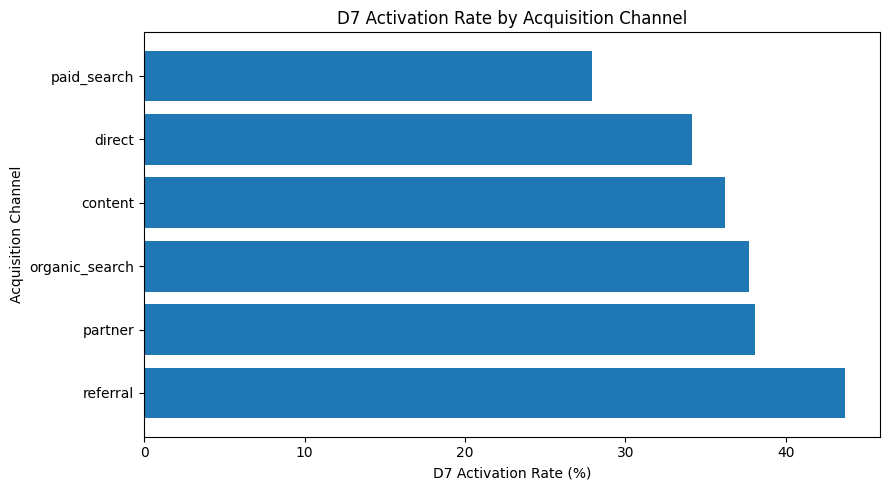

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
activation_summary = activation[
    [
        "acquisition_channel",
        "total_signups",
        "activated_d7_users",
        "d7_activation_rate_pct",
        "median_time_to_activate_days",
        "p90_time_to_activate_days"
    ]
].sort_values("d7_activation_rate_pct", ascending=False)

display(activation_summary)

plt.figure(figsize=(9, 5))
plt.barh(
    activation_summary["acquisition_channel"],
    activation_summary["d7_activation_rate_pct"]
)
plt.xlabel("D7 Activation Rate (%)")
plt.ylabel("Acquisition Channel")
plt.title("D7 Activation Rate by Acquisition Channel")
plt.tight_layout()
plt.show()

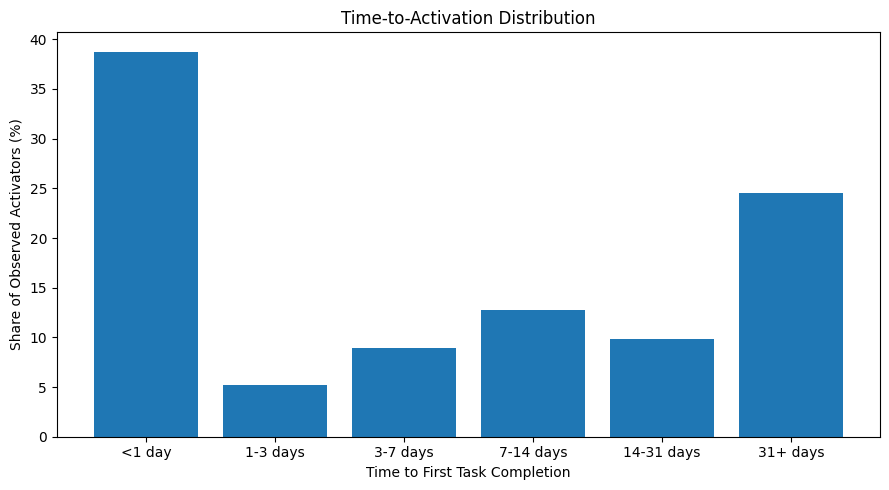

In [ ]:
bucket_columns = [
    "under_1_day",
    "days_1_to_3",
    "days_3_to_7",
    "days_7_to_14",
    "days_14_to_31",
    "days_31_plus"
]

bucket_labels = [
    "<1 day",
    "1-3 days",
    "3-7 days",
    "7-14 days",
    "14-31 days",
    "31+ days"
]

bucket_totals = activation[bucket_columns].sum()
total_activators = bucket_totals.sum()

bucket_percentages = bucket_totals / total_activators * 100

plt.figure(figsize=(9, 5))
plt.bar(bucket_labels, bucket_percentages)
plt.xlabel("Time to First Task Completion")
plt.ylabel("Share of Observed Activators (%)")
plt.title("Time-to-Activation Distribution")
plt.tight_layout()
plt.show()

In [ ]:
retention = client.query("""
    SELECT *
    FROM `product-analysis-509809.saas_analytics_dbt.mart_retention`
    ORDER BY signup_cohort_month, activation_status
""").to_dataframe()

display(retention)

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,signup_cohort_month,activation_status,cohort_users,d1_retained_users,d1_retention_rate,d7_retained_users,d7_retention_rate,d30_retained_users,d30_retention_rate
0,2026-01-01,activated_d7,2625,305,11.62,218,8.30,65,2.48
1,2026-01-01,not_activated_d7,4647,139,2.99,181,3.89,76,1.64
2,2026-02-01,activated_d7,2452,285,11.62,203,8.28,53,2.16
3,2026-02-01,not_activated_d7,4252,135,3.17,170,4.00,69,1.62
4,2026-03-01,activated_d7,2644,306,11.57,224,8.47,72,2.72
5,2026-03-01,not_activated_d7,4615,148,3.21,202,4.38,77,1.67
6,2026-04-01,activated_d7,2626,295,11.23,239,9.10,71,2.70
7,2026-04-01,not_activated_d7,4564,152,3.33,201,4.40,92,2.02
8,2026-05-01,activated_d7,2663,321,12.05,229,8.60,58,2.18
9,2026-05-01,not_activated_d7,4736,158,3.34,212,4.48,65,1.37


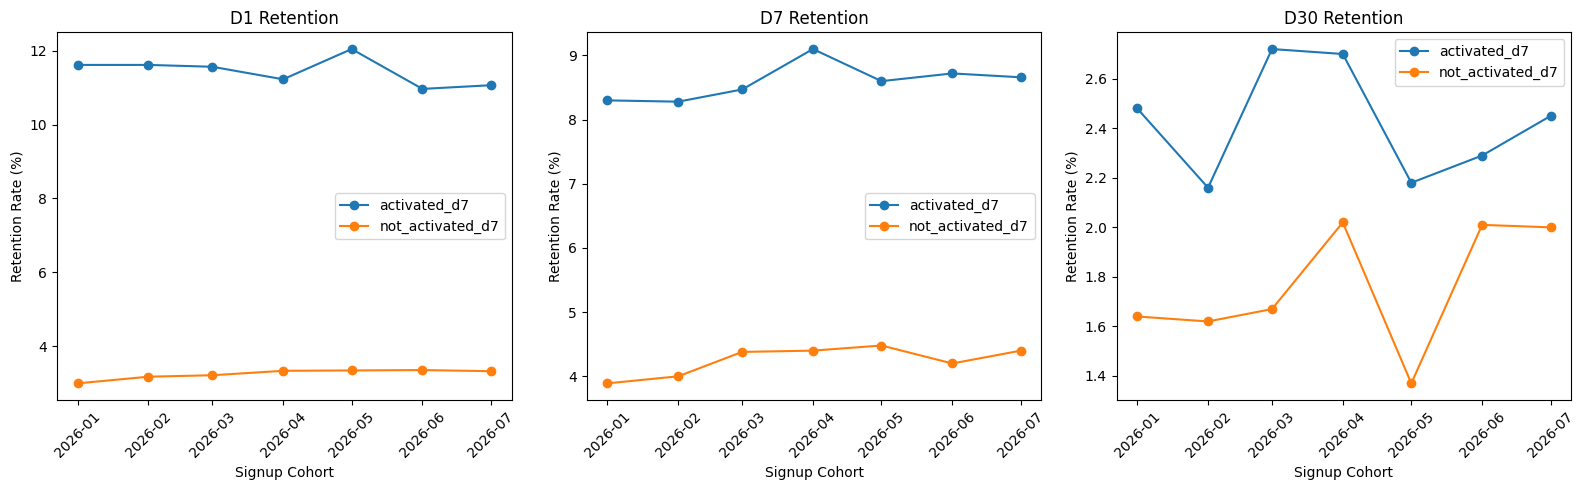

In [ ]:
retention["signup_cohort_month"] = pd.to_datetime(
    retention["signup_cohort_month"]
)

metrics = [
    ("d1_retention_rate", "D1 Retention"),
    ("d7_retention_rate", "D7 Retention"),
    ("d30_retention_rate", "D30 Retention")
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (metric, title) in zip(axes, metrics):
    for status, group in retention.groupby("activation_status"):
        group = group.sort_values("signup_cohort_month")

        ax.plot(
            group["signup_cohort_month"],
            group[metric],
            marker="o",
            label=status
        )

    ax.set_title(title)
    ax.set_ylabel("Retention Rate (%)")
    ax.set_xlabel("Signup Cohort")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

funnel = client.query("""
    SELECT *
    FROM `product-analysis-509809.saas_analytics_dbt.mart_funnel`
    ORDER BY total_signups DESC
""").to_dataframe()

display(funnel)

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,acquisition_channel,total_signups,signup_completed_users,signup_completion_dropoff_users,signup_completion_conversion_rate_pct,project_created_users,project_creation_dropoff_users,project_creation_conversion_rate_pct,task_created_users,task_creation_dropoff_users,task_creation_conversion_rate_pct,task_completed_users,task_completion_dropoff_users,task_completion_conversion_rate_pct,overall_signup_to_task_completion_rate_pct
0,organic_search,12145,12145,0,100.0,11318,827,93.19,9821,1497,86.77,8653,1168,88.11,71.25
1,referral,9085,9085,0,100.0,8702,383,95.78,7801,901,89.65,7028,773,90.09,77.36
2,paid_search,8929,8929,0,100.0,7621,1308,85.35,6121,1500,80.32,5096,1025,83.25,57.07
3,direct,7470,7470,0,100.0,6810,660,91.16,5768,1042,84.70,4994,774,86.58,66.85
4,content,7449,7449,0,100.0,6769,680,90.87,5789,980,85.52,5031,758,86.91,67.54
5,partner,4922,4922,0,100.0,4608,314,93.62,3959,649,85.92,3521,438,88.94,71.54


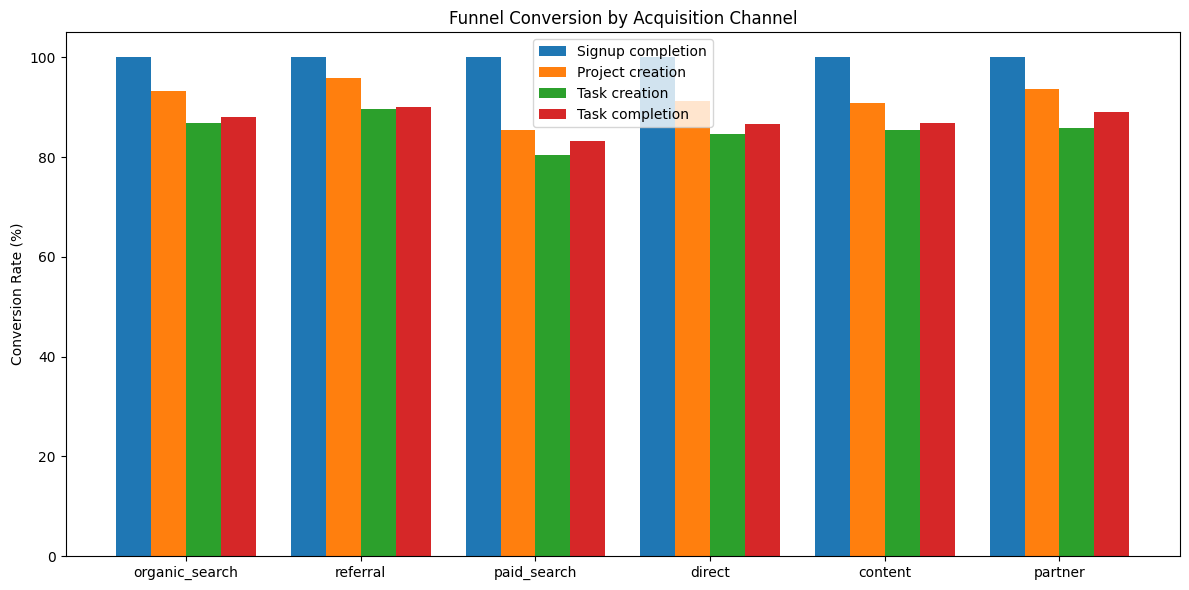

In [ ]:
stages = {
    "signup_completion_conversion_rate_pct": "Signup completion",
    "project_creation_conversion_rate_pct": "Project creation",
    "task_creation_conversion_rate_pct": "Task creation",
    "task_completion_conversion_rate_pct": "Task completion"
}

x = np.arange(len(funnel))
width = 0.2

fig, ax = plt.subplots(figsize=(12, 6))

for i, (column, label) in enumerate(stages.items()):
    ax.bar(
        x + (i - 1.5) * width,
        funnel[column],
        width,
        label=label
    )

ax.set_xticks(x)
ax.set_xticklabels(funnel["acquisition_channel"])
ax.set_ylabel("Conversion Rate (%)")
ax.set_title("Funnel Conversion by Acquisition Channel")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
experiment = client.query("""
    SELECT *
    FROM `product-analysis-509809.saas_analytics_dbt.mart_experiment_impact`
    ORDER BY experiment_id, variant, outcome_event
""").to_dataframe()

display(experiment)

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,experiment_id,experiment_name,variant,outcome_event,assigned_users,users_with_outcome_7d,outcome_rate_pct
0,EXP001,onboarding_redesign,new_onboarding,onboarding_step_completed,19665,13284,67.55
1,EXP001,onboarding_redesign,old_onboarding,onboarding_step_completed,19753,13299,67.33
2,EXP002,collaboration_prompt,no_prompt,invite_accepted,15673,1356,8.65
3,EXP002,collaboration_prompt,no_prompt,invite_sent,15673,2247,14.34
4,EXP002,collaboration_prompt,prompt_shown,invite_accepted,15835,1653,10.44
5,EXP002,collaboration_prompt,prompt_shown,invite_sent,15835,2348,14.83


In [ ]:
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)
from statsmodels.stats.multitest import multipletests

comparisons = [
    ("EXP001", "onboarding_step_completed", "new_onboarding", "old_onboarding"),
    ("EXP002", "invite_sent", "prompt_shown", "no_prompt"),
    ("EXP002", "invite_accepted", "prompt_shown", "no_prompt")
]

results = []

for exp_id, outcome, treatment, control in comparisons:

    t = experiment[
        (experiment["experiment_id"] == exp_id) &
        (experiment["outcome_event"] == outcome) &
        (experiment["variant"] == treatment)
    ].iloc[0]

    c = experiment[
        (experiment["experiment_id"] == exp_id) &
        (experiment["outcome_event"] == outcome) &
        (experiment["variant"] == control)
    ].iloc[0]

    t_users = int(t["users_with_outcome_7d"])
    t_total = int(t["assigned_users"])

    c_users = int(c["users_with_outcome_7d"])
    c_total = int(c["assigned_users"])

    t_rate = t_users / t_total
    c_rate = c_users / c_total

    absolute_lift = (t_rate - c_rate) * 100
    relative_lift = ((t_rate - c_rate) / c_rate) * 100

    _, p_value = proportions_ztest(
        [t_users, c_users],
        [t_total, c_total]
    )

    ci_low, ci_high = confint_proportions_2indep(
        t_users,
        t_total,
        c_users,
        c_total,
        method="newcomb"
    )

    results.append({
        "experiment": exp_id,
        "outcome": outcome,
        "control_rate_pct": c_rate * 100,
        "treatment_rate_pct": t_rate * 100,
        "absolute_lift_pp": absolute_lift,
        "relative_lift_pct": relative_lift,
        "ci_lower_pp": ci_low * 100,
        "ci_upper_pp": ci_high * 100,
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

results_df["adjusted_p_value"] = multipletests(
    results_df["p_value"],
    method="holm"
)[1]

results_df["significant"] = results_df["adjusted_p_value"] < 0.05

display(results_df.round(5))

,experiment,outcome,control_rate_pct,treatment_rate_pct,absolute_lift_pp,relative_lift_pct,ci_lower_pp,ci_upper_pp,p_value,adjusted_p_value,significant
0,EXP001,onboarding_step_completed,67.32648,67.55149,0.22501,0.33420,-0.70017,1.15009,0.63361,0.63361,False
1,EXP002,invite_sent,14.33676,14.82791,0.49116,3.42585,-0.28839,1.27051,0.21681,0.43361,False
2,EXP002,invite_accepted,8.65182,10.43890,1.78708,20.65553,1.13856,2.43594,0.00000,0.00000,True


c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,company_size,total_users,eligible_users,activated_users,activation_rate_pct
0,11-50,19714,19714,7204,36.54
1,51-200,12454,12454,4944,39.70
2,1-10,12403,12403,3828,30.86
3,201-1000,5429,5429,2189,40.32


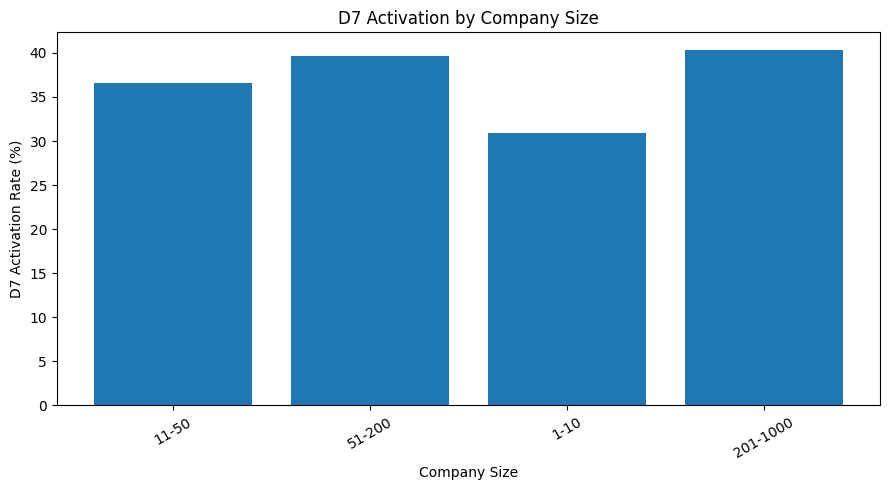

In [ ]:
company_segments = client.query("""
    SELECT
        COALESCE(company_size, 'Unknown') AS company_size,
        COUNT(*) AS total_users,
        COUNTIF(activated_d7 IS NOT NULL) AS eligible_users,
        COUNTIF(activated_d7 IS TRUE) AS activated_users,
        ROUND(
            SAFE_DIVIDE(
                COUNTIF(activated_d7 IS TRUE),
                COUNTIF(activated_d7 IS NOT NULL)
            ) * 100,
            2
        ) AS activation_rate_pct
    FROM `product-analysis-509809.saas_analytics_dbt.mart_user_metrics`
    GROUP BY 1
    ORDER BY total_users DESC
""").to_dataframe()

display(company_segments)

plt.figure(figsize=(9, 5))
plt.bar(
    company_segments["company_size"],
    company_segments["activation_rate_pct"]
)
plt.xlabel("Company Size")
plt.ylabel("D7 Activation Rate (%)")
plt.title("D7 Activation by Company Size")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,role,total_users,activated_users,activation_rate_pct
0,member,25557,9327,36.49
1,admin,17122,6243,36.46
2,manager,7321,2595,35.45


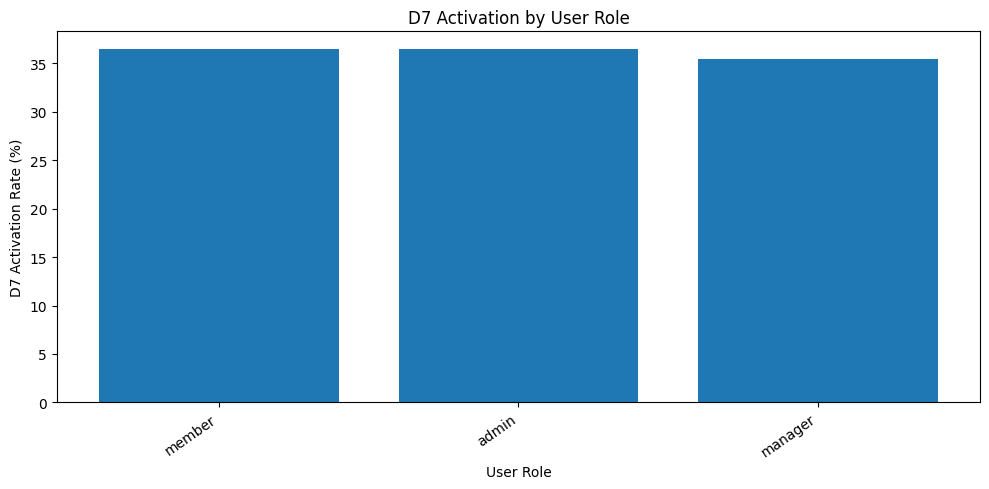

In [ ]:
role_segments = client.query("""
    SELECT
        COALESCE(role, 'Unknown') AS role,
        COUNT(*) AS total_users,
        COUNTIF(activated_d7) AS activated_users,
        ROUND(
            SAFE_DIVIDE(COUNTIF(activated_d7), COUNT(*)) * 100,
            2
        ) AS activation_rate_pct
    FROM `product-analysis-509809.saas_analytics_dbt.mart_user_metrics`
    GROUP BY 1
    ORDER BY total_users DESC
""").to_dataframe()

display(role_segments)

plt.figure(figsize=(10, 5))
plt.bar(role_segments["role"], role_segments["activation_rate_pct"])
plt.ylabel("D7 Activation Rate (%)")
plt.xlabel("User Role")
plt.title("D7 Activation by User Role")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,device_type,total_users,activated_users,activation_rate_pct
0,desktop,36040,13103,36.36
1,mobile,11931,4350,36.46
2,tablet,2029,712,35.09


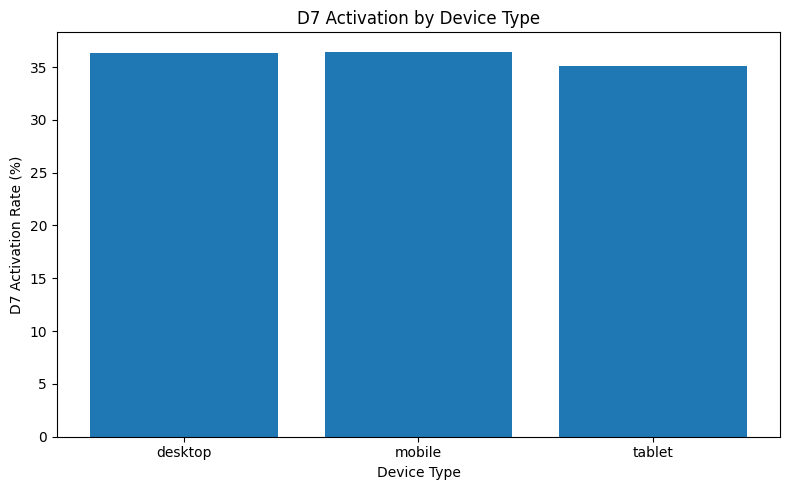

In [ ]:
device_segments = client.query("""
    SELECT
        COALESCE(device_type, 'Unknown') AS device_type,
        COUNT(*) AS total_users,
        COUNTIF(activated_d7) AS activated_users,
        ROUND(
            SAFE_DIVIDE(COUNTIF(activated_d7), COUNT(*)) * 100,
            2
        ) AS activation_rate_pct
    FROM `product-analysis-509809.saas_analytics_dbt.mart_user_metrics`
    GROUP BY 1
    ORDER BY total_users DESC
""").to_dataframe()

display(device_segments)

plt.figure(figsize=(8, 5))
plt.bar(device_segments["device_type"], device_segments["activation_rate_pct"])
plt.ylabel("D7 Activation Rate (%)")
plt.xlabel("Device Type")
plt.title("D7 Activation by Device Type")
plt.tight_layout()
plt.show()

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,industry,total_users,activated_users,activation_rate_pct
0,technology,11492,4190,36.46
1,professional_services,8531,3126,36.64
2,education,5953,2168,36.42
3,financial_services,5042,1791,35.52
4,healthcare,4994,1839,36.82
5,retail,4994,1781,35.66
6,manufacturing,4914,1783,36.28
7,media,4080,1487,36.45


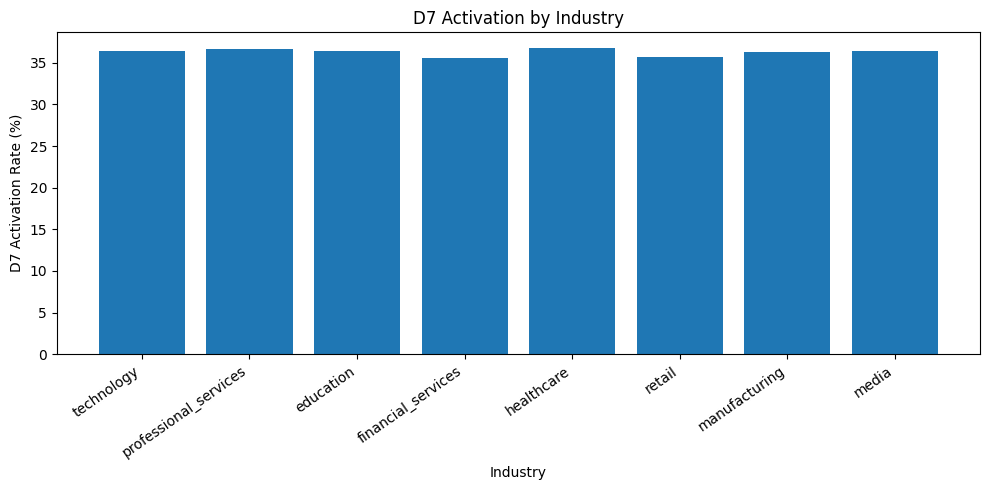

In [ ]:
industry_segments = client.query("""
    SELECT
        COALESCE(industry, 'Unknown') AS industry,
        COUNT(*) AS total_users,
        COUNTIF(activated_d7) AS activated_users,
        ROUND(
            SAFE_DIVIDE(COUNTIF(activated_d7), COUNT(*)) * 100,
            2
        ) AS activation_rate_pct
    FROM `product-analysis-509809.saas_analytics_dbt.mart_user_metrics`
    GROUP BY 1
    ORDER BY total_users DESC
""").to_dataframe()

display(industry_segments)

plt.figure(figsize=(10, 5))
plt.bar(industry_segments["industry"], industry_segments["activation_rate_pct"])
plt.ylabel("D7 Activation Rate (%)")
plt.xlabel("Industry")
plt.title("D7 Activation by Industry")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
engagement = client.query("""
    SELECT
        IF(activated_d7, 'Activated', 'Not Activated') AS activation_status,
        COUNT(*) AS users,
        ROUND(AVG(active_days), 2) AS avg_active_days,
        ROUND(AVG(total_activity_events), 2) AS avg_activity_events,
        ROUND(AVG(total_sessions), 2) AS avg_sessions,
        ROUND(AVG(avg_session_duration_seconds), 2) AS avg_session_duration_seconds
    FROM `product-analysis-509809.saas_analytics_dbt.mart_user_metrics`
    GROUP BY 1
    ORDER BY 1
""").to_dataframe()

display(engagement)

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,activation_status,users,avg_active_days,avg_activity_events,avg_sessions,avg_session_duration_seconds
0,Activated,18165,4.23,15.71,4.85,777.62
1,Not Activated,31835,2.86,8.37,3.76,777.29


In [ ]:
weighted_retention = (
    retention.groupby("activation_status", as_index=False)
    .agg(
        cohort_users=("cohort_users", "sum"),
        d1_retained=("d1_retained_users", "sum"),
        d7_retained=("d7_retained_users", "sum"),
        d30_retained=("d30_retained_users", "sum")
    )
)

for day in ["d1", "d7", "d30"]:
    weighted_retention[f"{day}_retention_pct"] = (
        weighted_retention[f"{day}_retained"]
        / weighted_retention["cohort_users"] * 100
    ).round(2)

display(weighted_retention)

,activation_status,cohort_users,d1_retained,d7_retained,d30_retained,d1_retention_pct,d7_retention_pct,d30_retention_pct
0,activated_d7,18165,2080,1561,441,11.45,8.59,2.43
1,not_activated_d7,31835,1033,1354,560,3.24,4.25,1.76


In [ ]:
retention_summary = (
    retention.groupby("activation_status")
    [["d1_retention_rate", "d7_retention_rate", "d30_retention_rate"]]
    .mean()
    .round(2)
)

display(retention_summary)

,d1_retention_rate,d7_retention_rate,d30_retention_rate
activation_status,,,
activated_d7,11.45,8.59,2.43
not_activated_d7,3.24,4.25,1.76


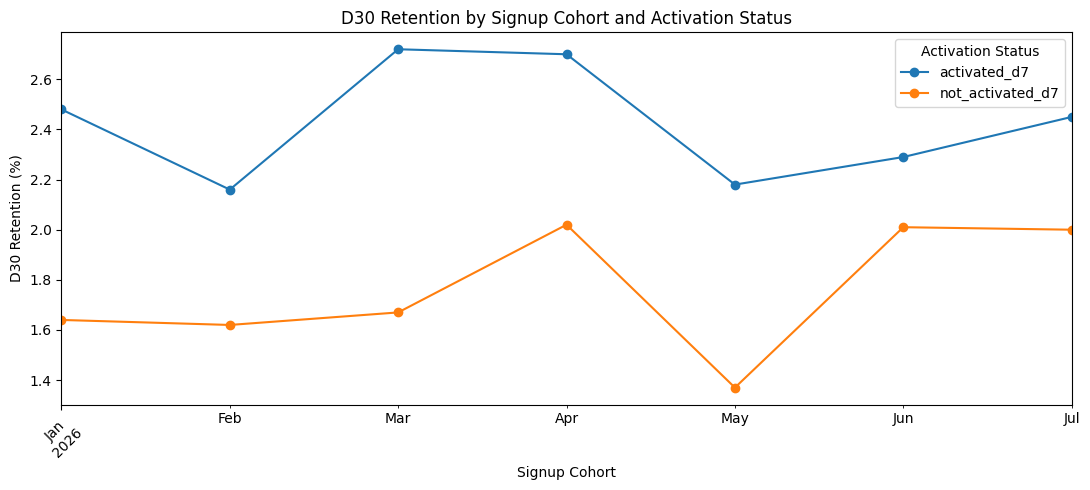

In [ ]:
retention_plot = retention.pivot(
    index="signup_cohort_month",
    columns="activation_status",
    values="d30_retention_rate"
)

retention_plot.plot(figsize=(11, 5), marker="o")
plt.title("D30 Retention by Signup Cohort and Activation Status")
plt.xlabel("Signup Cohort")
plt.ylabel("D30 Retention (%)")
plt.xticks(rotation=45)
plt.legend(title="Activation Status")
plt.tight_layout()
plt.show()

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,week_start_date,weekly_task_completing_users,task_completion_events
0,2026-01-05,640,929
1,2026-01-12,861,1283
2,2026-01-19,1049,1561
3,2026-01-26,1182,1757
4,2026-02-02,1317,1923
5,2026-02-09,1407,2032
6,2026-02-16,1480,2185
7,2026-02-23,1613,2393
8,2026-03-02,1640,2370
9,2026-03-09,1723,2467


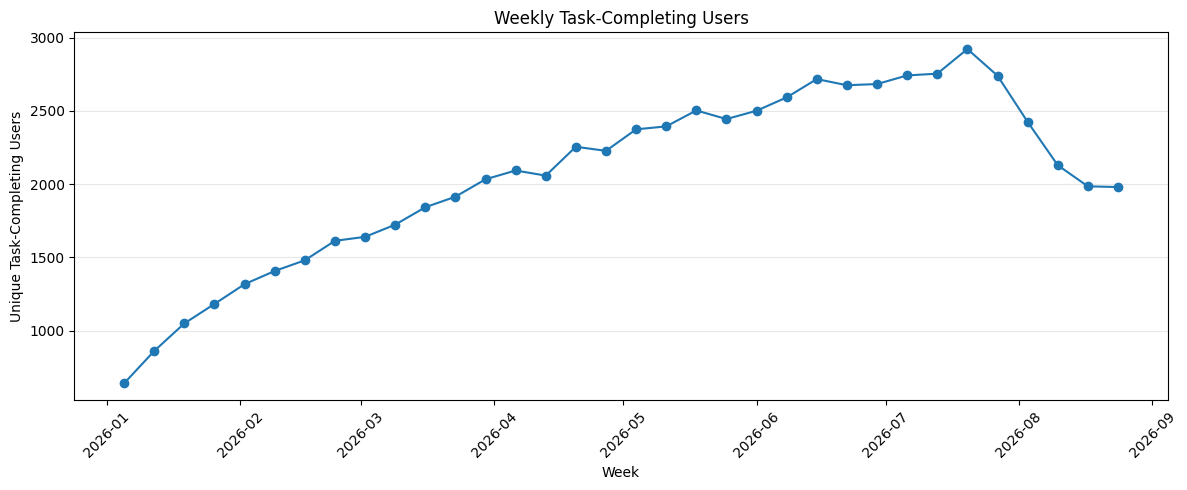

In [ ]:
weekly = client.query("""
    SELECT
        week_start_date,
        weekly_task_completing_users,
        task_completion_events
    FROM `product-analysis-509809.saas_analytics_dbt.mart_weekly_task_completing_users`
    WHERE is_complete_week = TRUE
    ORDER BY week_start_date
""").to_dataframe()

display(weekly)

plt.figure(figsize=(12, 5))
plt.plot(
    weekly["week_start_date"],
    weekly["weekly_task_completing_users"],
    marker="o"
)
plt.title("Weekly Task-Completing Users")
plt.xlabel("Week")
plt.ylabel("Unique Task-Completing Users")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


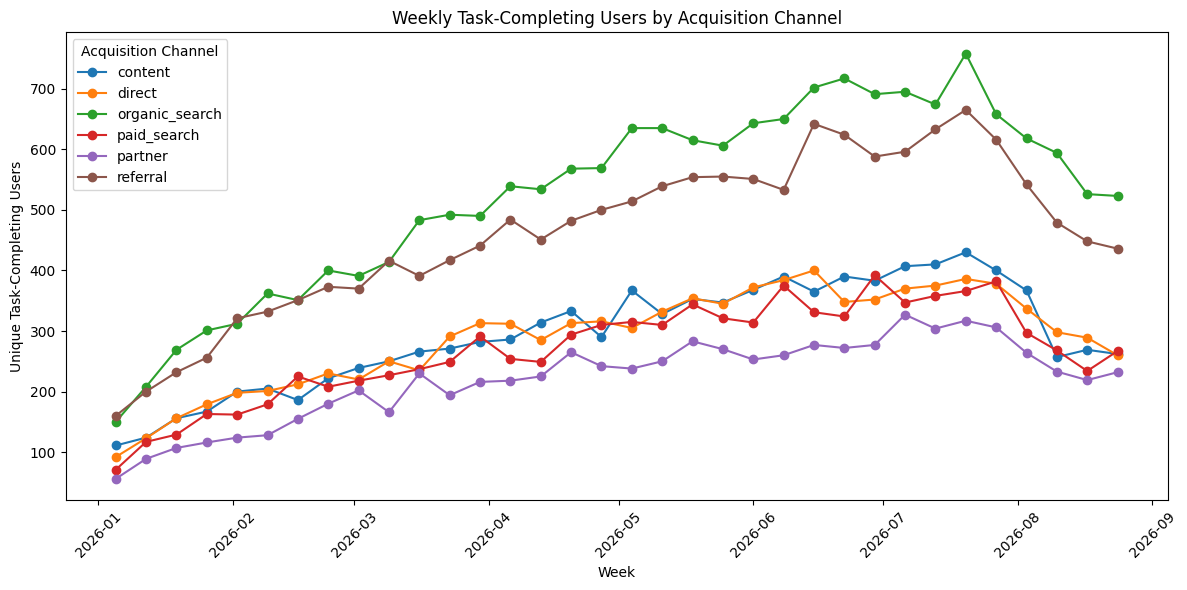

In [ ]:
weekly_channels = client.query("""
    SELECT
        w.week_start_date,
        u.acquisition_channel,
        COUNT(DISTINCT IF(
            a.task_completion_event_count > 0,
            a.user_id,
            NULL
        )) AS weekly_task_completing_users
    FROM `product-analysis-509809.saas_analytics_dbt.int_user_activity_daily` a
    JOIN `product-analysis-509809.saas_analytics_dbt.stg_users` u
        USING (user_id)
    JOIN `product-analysis-509809.saas_analytics_dbt.mart_weekly_task_completing_users` w
        ON DATE_TRUNC(a.activity_date, WEEK(MONDAY)) = w.week_start_date
    WHERE w.is_complete_week = TRUE
    GROUP BY 1, 2
    ORDER BY 1, 2
""").to_dataframe()

channel_pivot = weekly_channels.pivot(
    index="week_start_date",
    columns="acquisition_channel",
    values="weekly_task_completing_users"
).fillna(0)

channel_pivot.plot(figsize=(12, 6), marker="o")
plt.title("Weekly Task-Completing Users by Acquisition Channel")
plt.xlabel("Week")
plt.ylabel("Unique Task-Completing Users")
plt.legend(title="Acquisition Channel")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,week_start_date,new_active_users,existing_active_users
0,2026-01-05,491,149
1,2026-01-12,487,374
2,2026-01-19,506,543
3,2026-01-26,500,682
4,2026-02-02,508,809
5,2026-02-09,491,916
6,2026-02-16,527,953
7,2026-02-23,525,1088
8,2026-03-02,509,1131
9,2026-03-09,489,1234


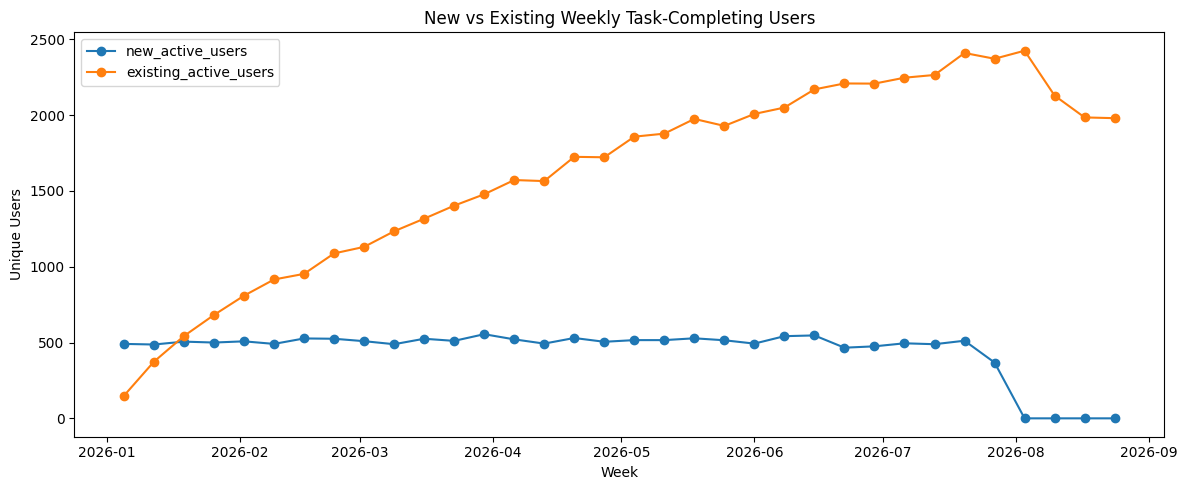

In [ ]:
weekly_user_mix = client.query("""
    SELECT
        w.week_start_date,
        COUNT(DISTINCT IF(
            DATE(u.signup_timestamp, 'UTC')
                BETWEEN w.week_start_date AND w.week_end_date,
            a.user_id, NULL
        )) AS new_active_users,
        COUNT(DISTINCT IF(
            DATE(u.signup_timestamp, 'UTC') < w.week_start_date,
            a.user_id, NULL
        )) AS existing_active_users
    FROM `product-analysis-509809.saas_analytics_dbt.int_user_activity_daily` a
    JOIN `product-analysis-509809.saas_analytics_dbt.stg_users` u
        USING (user_id)
    JOIN `product-analysis-509809.saas_analytics_dbt.mart_weekly_task_completing_users` w
        ON DATE_TRUNC(a.activity_date, WEEK(MONDAY)) = w.week_start_date
    WHERE w.is_complete_week = TRUE
      AND a.task_completion_event_count > 0
    GROUP BY 1
    ORDER BY 1
""").to_dataframe()

display(weekly_user_mix)

weekly_user_mix.set_index("week_start_date").plot(
    figsize=(12, 5), marker="o"
)
plt.title("New vs Existing Weekly Task-Completing Users")
plt.ylabel("Unique Users")
plt.xlabel("Week")
plt.tight_layout()
plt.show()

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,week_start,new_signups
0,2025-12-29,973
1,2026-01-05,1621
2,2026-01-12,1599
3,2026-01-19,1674
4,2026-01-26,1664
5,2026-02-02,1690
6,2026-02-09,1607
7,2026-02-16,1692
8,2026-02-23,1669
9,2026-03-02,1656


,stage,users,users_lost_from_previous_stage,conversion_from_previous_stage_pct,conversion_from_signup_pct
0,Total Signups,50000,0,NaN,100.00
1,Signup Completed,50000,0,100.00,100.00
2,Project Created,45828,4172,91.66,91.66
3,Task Created,39259,6569,85.67,78.52
4,Task Completed,34323,4936,87.43,68.65


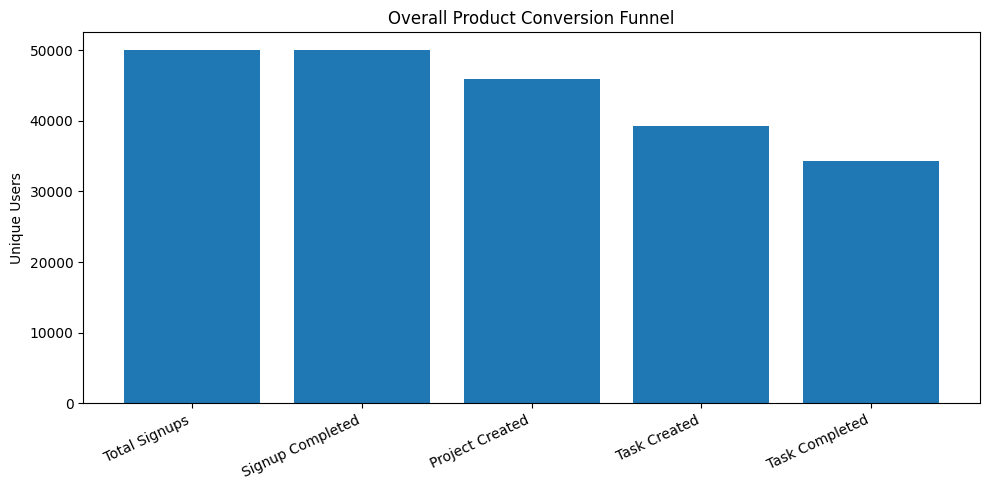

In [ ]:
weekly_signups = client.query("""
    SELECT
        DATE_TRUNC(DATE(signup_timestamp, 'UTC'), WEEK(MONDAY)) AS week_start,
        COUNT(DISTINCT user_id) AS new_signups
    FROM `product-analysis-509809.saas_analytics_dbt.stg_users`
    GROUP BY 1
    ORDER BY 1
""").to_dataframe()

display(weekly_signups)

funnel_stages = [
    ("Total Signups", "total_signups"),
    ("Signup Completed", "signup_completed_users"),
    ("Project Created", "project_created_users"),
    ("Task Created", "task_created_users"),
    ("Task Completed", "task_completed_users")
]

funnel_rows = []
previous_users = None
total_signups = int(funnel["total_signups"].sum())

for stage, column in funnel_stages:
    users = int(funnel[column].sum())

    funnel_rows.append({
        "stage": stage,
        "users": users,
        "users_lost_from_previous_stage": (
            previous_users - users if previous_users is not None else 0
        ),
        "conversion_from_previous_stage_pct": (
            round(users / previous_users * 100, 2)
            if previous_users else np.nan
        ),
        "conversion_from_signup_pct": round(users / total_signups * 100, 2)
        if total_signups else np.nan
    })

    previous_users = users

funnel_totals = pd.DataFrame(funnel_rows)
display(funnel_totals)

plt.figure(figsize=(10, 5))
plt.bar(funnel_totals["stage"], funnel_totals["users"])
plt.title("Overall Product Conversion Funnel")
plt.ylabel("Unique Users")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
weighted_rows = []

for status, group in retention.groupby("activation_status"):

    row = {"activation_status": status}

    for day in ["d1", "d7", "d30"]:

        rate_col = f"{day}_retention_rate"
        retained_col = f"{day}_retained_users"

        # Include only cohorts eligible for this retention period
        eligible = group[group[rate_col].notna()]

        eligible_users = eligible["cohort_users"].sum()
        retained_users = eligible[retained_col].sum()

        retention_pct = (
            (retained_users / eligible_users) * 100
            if eligible_users > 0
            else np.nan
        )

        row[f"{day}_eligible_users"] = int(eligible_users)
        row[f"{day}_retained_users"] = int(retained_users)
        row[f"{day}_retention_pct"] = round(retention_pct, 2)

    weighted_rows.append(row)


# Create and display the final table
weighted_retention = pd.DataFrame(weighted_rows)

display(weighted_retention)

,activation_status,d1_eligible_users,d1_retained_users,d1_retention_pct,d7_eligible_users,d7_retained_users,d7_retention_pct,d30_eligible_users,d30_retained_users,d30_retention_pct
0,activated_d7,18165,2080,11.45,18165,1561,8.59,18165,441,2.43
1,not_activated_d7,31835,1033,3.24,31835,1354,4.25,31835,560,1.76


In [42]:
import numpy as np
import pandas as pd

from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests


# Fetch fresh segment data from BigQuery
segment_dimensions = {
    "Company Size": "company_size",
    "Role": "role",
    "Device Type": "device_type",
    "Industry": "industry"
}

segment_frames = {}

for dimension, column in segment_dimensions.items():

    query = f"""
        SELECT
            COALESCE(CAST({column} AS STRING), 'Unknown') AS category,
            COUNT(*) AS total_users,
            COUNTIF(activated_d7 IS NOT NULL) AS eligible_users,
            COUNTIF(activated_d7 IS TRUE) AS activated_users
        FROM `product-analysis-509809.saas_analytics_dbt.mart_user_metrics`
        GROUP BY 1
        ORDER BY total_users DESC
    """

    segment_frames[dimension] = client.query(query).to_dataframe()


# Run chi-square tests and calculate Cramér's V
segment_results = []

for dimension, df in segment_frames.items():

    eligible_users = df["eligible_users"].astype(int)
    activated_users = df["activated_users"].astype(int)

    not_activated_users = eligible_users - activated_users

    contingency = np.column_stack([
        activated_users,
        not_activated_users
    ])

    chi2, p_value, degrees_of_freedom, expected = chi2_contingency(
        contingency
    )

    n = contingency.sum()
    min_dimension = min(contingency.shape[0] - 1, contingency.shape[1] - 1)

    cramers_v = (
        np.sqrt(chi2 / (n * min_dimension))
        if min_dimension > 0 and n > 0
        else np.nan
    )

    segment_results.append({
        "dimension": dimension,
        "categories": len(df),
        "eligible_users": int(n),
        "chi_square": chi2,
        "degrees_of_freedom": degrees_of_freedom,
        "p_value": p_value,
        "cramers_v": cramers_v
    })


# Apply Holm correction for multiple testing
segment_tests = pd.DataFrame(segment_results)

segment_tests["holm_adjusted_p"] = multipletests(
    segment_tests["p_value"],
    method="holm"
)[1]

segment_tests = segment_tests.sort_values("holm_adjusted_p")

display(segment_tests.round(5))

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(
c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(
c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(
c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,dimension,categories,eligible_users,chi_square,degrees_of_freedom,p_value,cramers_v,holm_adjusted_p
0,Company Size,4,50000,259.06666,3,0.00000,0.07198,0.00000
1,Role,3,50000,2.90253,2,0.23427,0.00762,0.70282
2,Device Type,3,50000,1.44407,2,0.48576,0.00537,0.97152
3,Industry,8,50000,3.40631,7,0.84505,0.00825,0.97152


c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,acquisition_channel,company_size,eligible_users,activated_users,activation_rate_pct
0,content,1-10,1886,579,30.70
1,content,11-50,2978,1099,36.90
2,content,201-1000,764,331,43.32
3,content,51-200,1821,687,37.73
4,direct,1-10,1837,524,28.52
5,direct,11-50,2871,962,33.51
6,direct,201-1000,828,317,38.29
7,direct,51-200,1934,748,38.68
8,organic_search,1-10,3026,940,31.06
9,organic_search,11-50,4728,1822,38.54


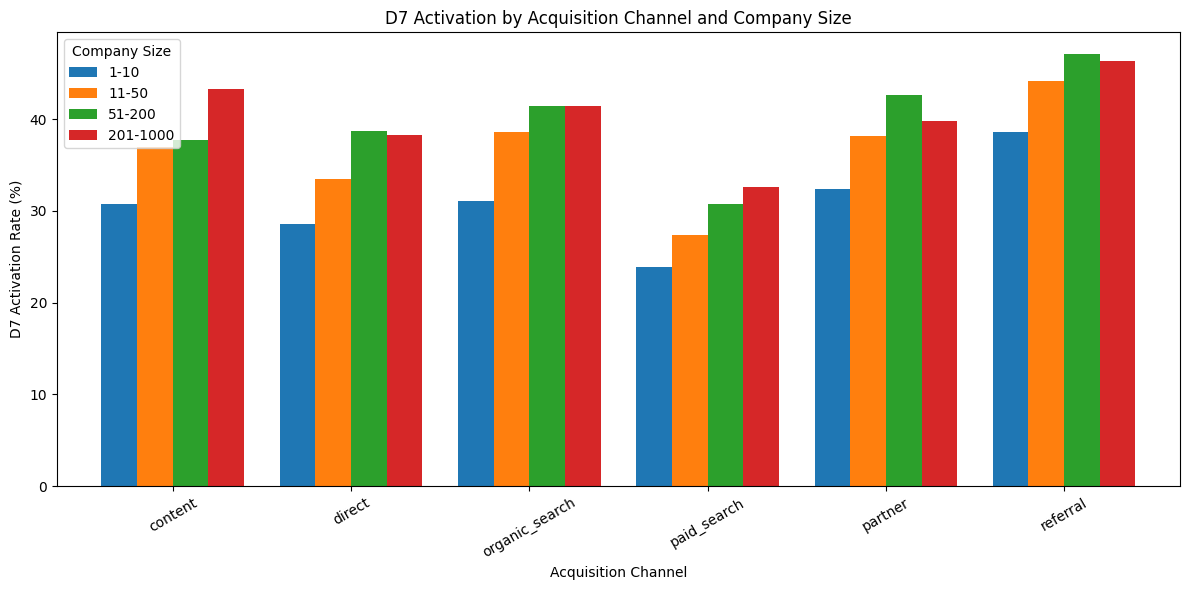

In [41]:
channel_company = client.query("""
    SELECT
        COALESCE(acquisition_channel, 'Unknown') AS acquisition_channel,
        COALESCE(company_size, 'Unknown') AS company_size,

        COUNTIF(activated_d7 IS NOT NULL) AS eligible_users,
        COUNTIF(activated_d7 IS TRUE) AS activated_users,

        SAFE_DIVIDE(
            COUNTIF(activated_d7 IS TRUE),
            COUNTIF(activated_d7 IS NOT NULL)
        ) * 100 AS activation_rate_pct

    FROM `product-analysis-509809.saas_analytics_dbt.mart_user_metrics`

    GROUP BY 1, 2
    ORDER BY 1, 2
""").to_dataframe()


# Display the underlying results
display(channel_company.round(2))


# Prepare data for plotting
plot_data = channel_company.pivot(
    index="acquisition_channel",
    columns="company_size",
    values="activation_rate_pct"
)

# Define logical company-size order
company_order = ["1-10", "11-50", "51-200", "201-1000"]

plot_data = plot_data.reindex(columns=company_order)

# Plot
ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("D7 Activation by Acquisition Channel and Company Size")
ax.set_xlabel("Acquisition Channel")
ax.set_ylabel("D7 Activation Rate (%)")
ax.legend(title="Company Size")
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
# -------------------- key findings --------------------

# activation
# d7 activation: 36.33% (18,165 / 50,000 users).
# referral had the highest activation (43.70%); paid search the lowest (27.92%).
# company size had a statistically significant but weak association with activation.
# role, device type and industry showed no significant association.

# engagement and retention
# activated users had more active days (4.23 vs 2.86),
# more events (15.71 vs 8.37) and more sessions (4.85 vs 3.76).
# d30 retention: 2.43% for activated users vs 1.76% for others.
# these are associations, not proof of causation.

# funnel
# the biggest drop-off occurred between project creation and task creation.
# referral had the highest signup-to-task-completion conversion (77.36%).
# paid search had the lowest (57.07%).

# product usage
# weekly task-completing users fell 32.2% from their july peak (2,922 to 1,980).
# existing active users also declined; the cause is unknown.

# experiments
# exp001: new onboarding showed no significant improvement.
# exp002: collaboration prompt increased invite acceptance by 1.79 pp
# (8.65% to 10.44%), statistically significant.
# invite sending did not improve significantly.

# -------------------- conclusion --------------------

# focus on improving early activation and the project-to-task journey.
# investigate the weak performance of paid-search users and the decline
# in existing active users.
# further test the collaboration prompt; it is the only intervention
# that showed a significant positive result.